### Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, LabelEncoder, StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Set visualization style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10,6)

### Load & Explore Data

In [3]:
df = pd.read_csv('Code/data/Students Performance .csv')
df

,Student_ID,Student_Age,Sex,High_School_Type,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,Target_Score
0,STUDENT1,19-22,Male,Other,50%,Yes,No,Private,0,Always,Yes,Yes,No,No,AA,51.9
1,STUDENT2,19-22,Male,Other,50%,Yes,No,Private,0,Always,Yes,No,Yes,Yes,AA,65.3
2,STUDENT3,19-22,Male,State,50%,No,No,Private,2,Never,No,No,No,Yes,AA,58.8
3,STUDENT4,18,Female,Private,50%,Yes,No,Bus,2,Always,No,Yes,No,No,AA,46.1
4,STUDENT5,19-22,Male,Private,50%,No,No,Bus,12,Always,Yes,No,Yes,Yes,AA,100.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
140,STUDENT141,19-22,Female,State,50%,Yes,Yes,Private,0,Always,No,Yes,No,Yes,CC,46.2
141,STUDENT142,18,Female,State,75%,No,No,Private,0,Never,No,Yes,Yes,No,CC,53.3
142,STUDENT143,18,Female,Private,75%,No,No,Private,0,Always,Yes,No,No,No,AA,46.6
143,STUDENT144,19-22,Female,State,75%,Yes,Yes,Bus,12,Sometimes,No,Yes,No,Yes,CB,100.0


In [4]:
df.head()

,Student_ID,Student_Age,Sex,High_School_Type,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,Target_Score
0,STUDENT1,19-22,Male,Other,50%,Yes,No,Private,0,Always,Yes,Yes,No,No,AA,51.9
1,STUDENT2,19-22,Male,Other,50%,Yes,No,Private,0,Always,Yes,No,Yes,Yes,AA,65.3
2,STUDENT3,19-22,Male,State,50%,No,No,Private,2,Never,No,No,No,Yes,AA,58.8
3,STUDENT4,18,Female,Private,50%,Yes,No,Bus,2,Always,No,Yes,No,No,AA,46.1
4,STUDENT5,19-22,Male,Private,50%,No,No,Bus,12,Always,Yes,No,Yes,Yes,AA,100.0


In [5]:
df.info

<bound method DataFrame.info of      Student_ID Student_Age     Sex High_School_Type Scholarship  \
0      STUDENT1       19-22    Male            Other         50%   
1      STUDENT2       19-22    Male            Other         50%   
2      STUDENT3       19-22    Male            State         50%   
3      STUDENT4          18  Female          Private         50%   
4      STUDENT5       19-22    Male          Private         50%   
..          ...         ...     ...              ...         ...   
140  STUDENT141       19-22  Female            State         50%   
141  STUDENT142          18  Female            State         75%   
142  STUDENT143          18  Female          Private         75%   
143  STUDENT144       19-22  Female            State         75%   
144  STUDENT145          18  Female          Private        100%   

    Additional_Work Sports_activity Transportation  Weekly_Study_Hours  \
0               Yes              No        Private                   0   
1  

In [6]:
df.shape

(145, 16)

In [7]:
df.columns

Index(['Student_ID', 'Student_Age', 'Sex', 'High_School_Type', 'Scholarship',
       'Additional_Work', 'Sports_activity', 'Transportation',
       'Weekly_Study_Hours', 'Attendance', 'Reading', 'Notes',
       'Listening_in_Class', 'Project_work', 'Grade', 'Target_Score'],
      dtype='object')

### Exploratory Data Analysis

In [8]:
# Check the data types and missing values
print("Data Types & Missing Values")
print("="*50)
info_df = pd.DataFrame({
    'Data Types': df.dtypes,
    'Missing Values': df.isnull().sum(),
    'Unique Values': df.nunique()
})

print(info_df)

Data Types & Missing Values
                   Data Types  Missing Values  Unique Values
Student_ID             object               0            145
Student_Age            object               0              3
Sex                    object               0              2
High_School_Type       object               0              3
Scholarship            object               0              5
Additional_Work        object               0              2
Sports_activity        object               0              2
Transportation         object               0              2
Weekly_Study_Hours      int64               0              4
Attendance             object               0              4
Reading                object               0              2
Notes                  object               0              3
Listening_in_Class     object               0              3
Project_work           object               0              2
Grade                  object               0            

In [9]:
df.describe()

,Weekly_Study_Hours,Target_Score
count,145.000000,145.000000
mean,2.331034,61.511724
std,4.249273,16.335074
min,0.000000,36.000000
25%,0.000000,49.700000
50%,0.000000,58.000000
75%,2.000000,67.200000
max,12.000000,100.000000


In [10]:
# Check for missing values in Scholarship
print(f"Missing Values in Scholarship: {df['Scholarship'].isnull().sum()}")

Missing Values in Scholarship: 0


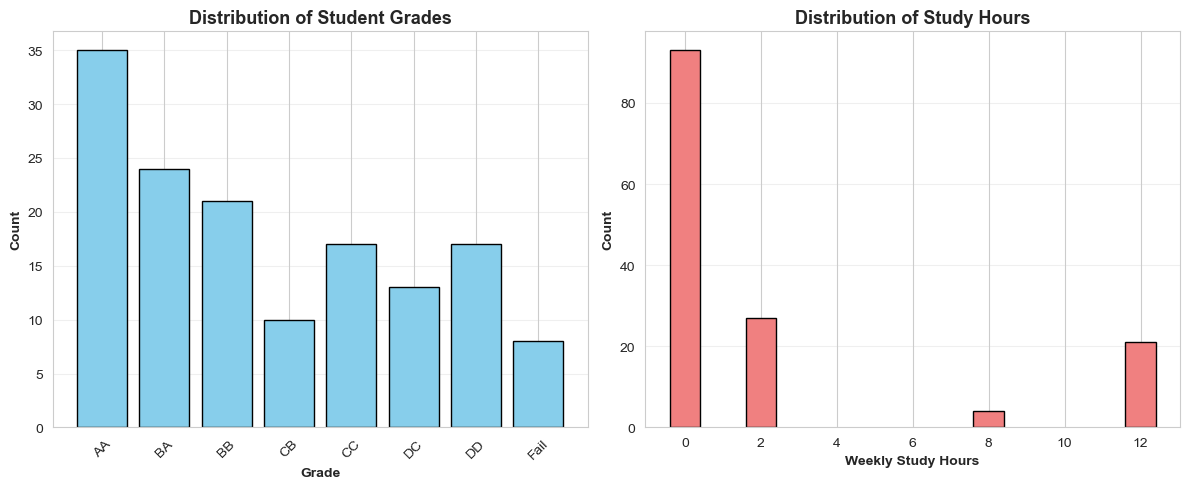


Grade Distribution
Grade
AA      35
BA      24
BB      21
CB      10
CC      17
DC      13
DD      17
Fail     8
Name: count, dtype: int64


In [11]:
# Visualize grade Distribution
plt.figure(figsize= (12,5))

plt.subplot(1,2,1)
grade_counts = df['Grade'].value_counts().sort_index()
plt.bar(grade_counts.index, grade_counts.values, color = 'skyblue', edgecolor = 'black')
plt.xlabel('Grade', fontweight = 'bold')
plt.ylabel('Count', fontweight = 'bold')
plt.title('Distribution of Student Grades', fontweight = 'bold', fontsize = 13)
plt.xticks(rotation = 45)
plt.grid(True, alpha = 0.3, axis = 'y')

plt.subplot(1,2,2)
study_hours_dist = df['Weekly_Study_Hours'].value_counts().sort_index()
plt.bar(study_hours_dist.index, study_hours_dist.values, color = 'lightcoral', edgecolor = 'black')
plt.xlabel('Weekly Study Hours', fontweight = 'bold')
plt.ylabel('Count', fontweight = 'bold')
plt.title('Distribution of Study Hours', fontweight = 'bold', fontsize = 13)
plt.grid(True, alpha = 0.3, axis = 'y')

plt.tight_layout()
plt.show()

print("\nGrade Distribution")
print(grade_counts)

### Analyze Target Variable (Target_Score)

In [12]:
if 'Target_Score' not in df.columns:
    raise ValueError('Target_Score column not found!')

df['Score'] = df['Target_Score']

print(f"\nScore Statistics: ")
print(df['Score'].describe())


Score Statistics: 
count    145.000000
mean      61.511724
std       16.335074
min       36.000000
25%       49.700000
50%       58.000000
75%       67.200000
max      100.000000
Name: Score, dtype: float64


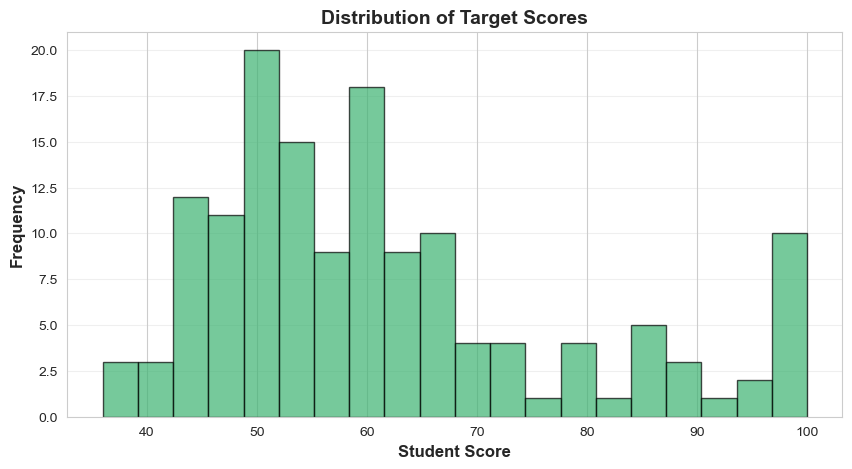

In [13]:
# Visualize score distribution
plt.figure(figsize= (10, 5))
plt.hist(df['Score'], bins = 20, color = 'mediumseagreen', edgecolor = 'black', alpha = 0.7)
plt.xlabel('Student Score', fontweight = 'bold', fontsize = 12)
plt.ylabel('Frequency', fontweight = 'bold', fontsize = 12)
plt.title('Distribution of Target Scores', fontweight = 'bold', fontsize = 14)
plt.grid(True, alpha = 0.3, axis = 'y')
plt.show()

In [14]:
df.head()

,Student_ID,Student_Age,Sex,High_School_Type,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,Target_Score,Score
0,STUDENT1,19-22,Male,Other,50%,Yes,No,Private,0,Always,Yes,Yes,No,No,AA,51.9,51.9
1,STUDENT2,19-22,Male,Other,50%,Yes,No,Private,0,Always,Yes,No,Yes,Yes,AA,65.3,65.3
2,STUDENT3,19-22,Male,State,50%,No,No,Private,2,Never,No,No,No,Yes,AA,58.8,58.8
3,STUDENT4,18,Female,Private,50%,Yes,No,Bus,2,Always,No,Yes,No,No,AA,46.1,46.1
4,STUDENT5,19-22,Male,Private,50%,No,No,Bus,12,Always,Yes,No,Yes,Yes,AA,100.0,100.0


### Data Preprocessing

In [15]:
# Encode categorical variables
categorical_cols = ['Sex', 'High_School_Type', 'Scholarship', 
                    'Additional_Work', 'Sports_activity', 'Transportation', 
                    'Attendance', 'Reading', 'Notes', 'Listening_in_Class', 
                    'Project_work']

label_encoders = {}
for col in categorical_cols:
    if col in df.columns:
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col].astype(str))
        label_encoders[col] = le

# Convert the age ranges to numerical
age_mapping = {'18': 18, '19-22': 20.5, '23-37':25}
df['Student_Age'] = df['Student_Age'].map(age_mapping)

print("✅ Categorical Variables encoded successfully")

✅ Categorical Variables encoded successfully


In [16]:
df.head()

,Student_ID,Student_Age,Sex,High_School_Type,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,Target_Score,Score
0,STUDENT1,20.5,1,0,3,1,0,1,0,1,1,2,1,0,AA,51.9,51.9
1,STUDENT2,20.5,1,0,3,1,0,1,0,1,1,1,2,1,AA,65.3,65.3
2,STUDENT3,20.5,1,2,3,0,0,1,2,2,0,1,1,1,AA,58.8,58.8
3,STUDENT4,18.0,0,1,3,1,0,0,2,1,0,2,1,0,AA,46.1,46.1
4,STUDENT5,20.5,1,1,3,0,0,0,12,1,1,1,2,1,AA,100.0,100.0


### Feature Selection and Corelation Analysis

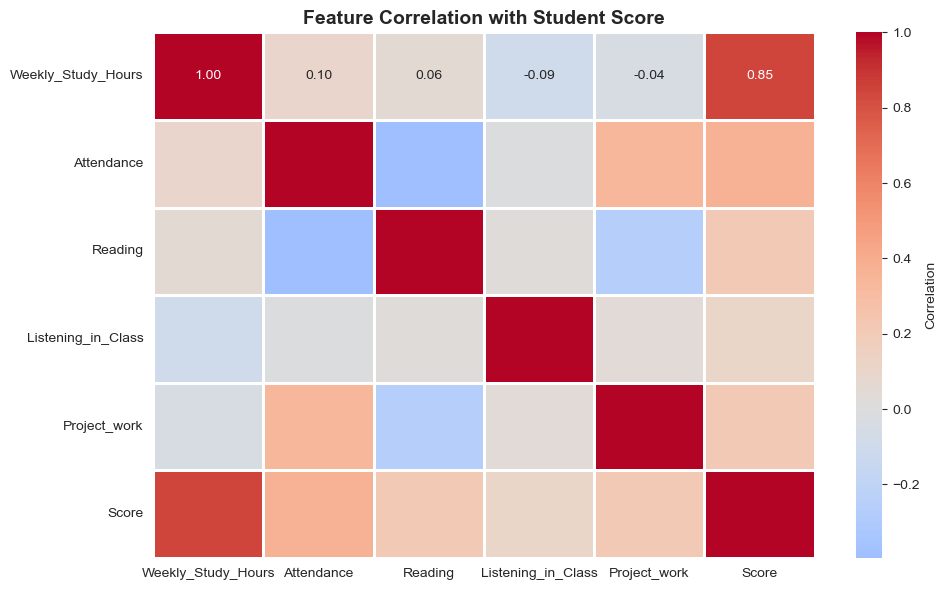


Correlation with Score (sorted):  
Score                 1.000000
Weekly_Study_Hours    0.845877
Attendance            0.370983
Project_work          0.220693
Reading               0.218091
Listening_in_Class    0.107116
Name: Score, dtype: float64


In [17]:
# Select Features for regression
feature_cols = ['Weekly_Study_Hours', 'Attendance', 'Reading', 
            'Listening_in_Class', 'Project_work']

# Calculate correlations
corr_data = df[feature_cols + ['Score']].corr()

# Plot correlation heatmap
plt.figure(figsize= (10,6))
sns.heatmap(corr_data, annot = True, cmap = 'coolwarm', center=0, fmt = '.2f',
            linewidths=1, cbar_kws= {'label': 'Correlation'})
plt.title("Feature Correlation with Student Score", fontweight = 'bold', fontsize = 14)
plt.tight_layout()
plt.show()

print("\nCorrelation with Score (sorted):  ")
print(corr_data['Score'].sort_values(ascending= False))

### Split Data into Training and Test sets

In [18]:
# Prepare features and target
X = df[feature_cols]
Y = df['Score']

# Split data
x_train, x_test, y_train, y_test = train_test_split(
    X, Y, test_size= 0.2, random_state= 42)

print(f"Training Set: {len(x_train)} samples")
print(f"Test set: {len(x_test)} samples")
print(f"features: {X.shape[1]}")

Training Set: 116 samples
Test set: 29 samples
features: 5


### Train Linear Regression Model (Degree 1)

In [19]:
# Train Linear Model
linear_model = LinearRegression()
linear_model.fit(x_train, y_train)

# Make predictions
y_train_pred_linear = linear_model.predict(x_train)
y_test_pred_linear = linear_model.predict(x_test)

# Calculate Metrics
train_r2_linear = r2_score(y_train, y_train_pred_linear)
test_r2_linear = r2_score(y_test, y_test_pred_linear)
test_rmse_linear = np.sqrt(mean_squared_error(y_test, y_test_pred_linear))
test_mae_linear = mean_absolute_error(y_test, y_test_pred_linear)

print("=" * 60)
print("Linear Regression (Degree 1) Results")
print("=" * 60)
print(f"Training R² Score: {train_r2_linear:.4f}")
print(f"Test R² Score: {test_r2_linear:.4f}")
print(f"Test RMSE Score: {test_rmse_linear:.2f}")
print(f"Test MAE Score: {test_mae_linear:.2f}")

Linear Regression (Degree 1) Results
Training R² Score: 0.9698
Test R² Score: 0.9692
Test RMSE Score: 2.83
Test MAE Score: 2.24


### Train Polynomial Regression (Degree 2)

In [20]:
# Create Polynomial Pipeline
poly_model = Pipeline([
    ('poly_features', PolynomialFeatures(degree = 2, include_bias= False)),
    ('scalar', StandardScaler()),
    ('regressor', LinearRegression())
])

# Train model
poly_model.fit(x_train, y_train)

# Make predictions
y_train_pred_poly = poly_model.predict(x_train)
y_test_pred_poly = poly_model.predict(x_test)

# Calculate Metrics
train_r2_poly = r2_score(y_train, y_train_pred_poly)
test_r2_poly = r2_score(y_test, y_test_pred_poly)
test_rmse_poly = np.sqrt(mean_squared_error(y_test, y_test_pred_poly))
test_mae_poly = mean_absolute_error(y_test, y_test_pred_poly)

print("=" * 60)
print("Polynomial Regression (Degree 2) Results")
print("=" * 60)
print(f"Training R² Score: {train_r2_poly:.4f}")
print(f"Test R² Score: {test_r2_poly:.4f}")
print(f"Test RMSE Score: {test_rmse_poly:.2f}")
print(f"Test MAE Score: {test_mae_poly:.2f}")

Polynomial Regression (Degree 2) Results
Training R² Score: 0.9792
Test R² Score: 0.9791
Test RMSE Score: 2.33
Test MAE Score: 1.83


### Compare Model Performance

In [23]:
comparison_df = pd.DataFrame({
    'Model': ['Linear (d=1)', 'Polynomial (d=2)'],
    'R² Score': [test_r2_linear, test_r2_poly],
    'RMSE Score': [test_rmse_linear, test_rmse_poly],
    'MAE Score': [test_mae_linear, test_mae_poly]
})

print("\n" + "=" * 60)
print("Model Comparrison Summary")
print("=" * 60)
print(comparison_df.to_string(index= False))
print("\n🏆 Best Model: ", comparison_df.loc[comparison_df['R² Score'].idxmax(), 'Model'])


Model Comparrison Summary
           Model  R² Score  RMSE Score  MAE Score
    Linear (d=1)  0.969198    2.826462   2.237061
Polynomial (d=2)  0.979080    2.329343   1.831890

🏆 Best Model:  Polynomial (d=2)


### Visualize Model Comparison

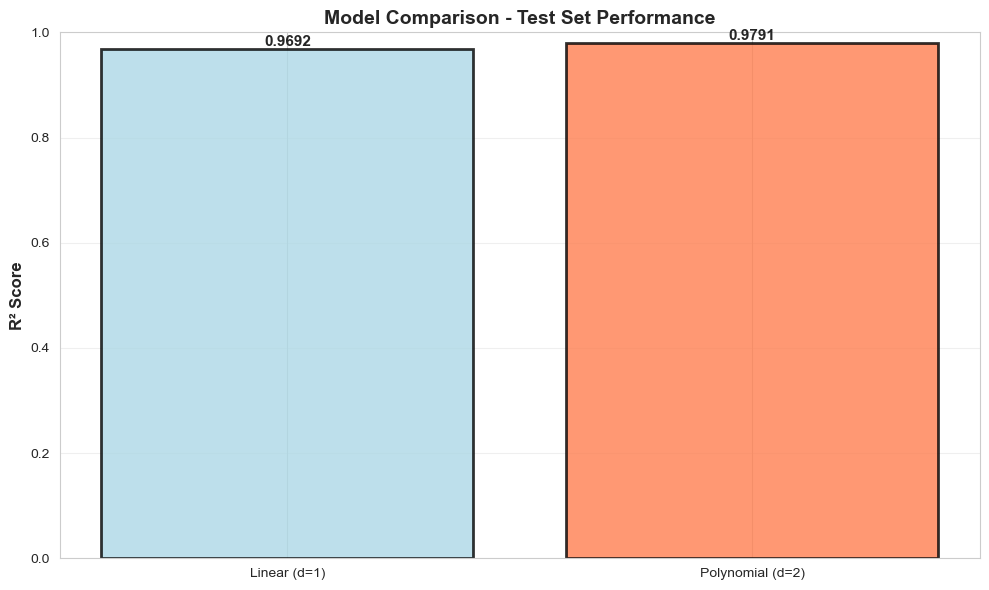

In [36]:
# Plot R² Score Comparison
fig, ax = plt.subplots(figsize = (10, 6))
bars = ax.bar(comparison_df['Model'], comparison_df['R² Score'], color = ['lightblue', 'coral'], 
              alpha = 0.8, edgecolor = 'black', linewidth = 2)
ax.set_ylabel('R² Score', fontsize = 12, fontweight = 'bold')
ax.set_title('Model Comparison - Test Set Performance', fontsize = 14, fontweight = 'bold')
ax.set_ylim(0, 1.0)
ax.grid(True, alpha = 0.3, axis = 'y')

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{height:.4f}',
            ha = 'center', va = 'bottom', fontweight = 'bold', fontsize = 11)

plt.tight_layout()
plt.show()

### Visualize Polynomial Fitting with Smooth Curves

In [50]:
# Use primary features for visualization
feature_idx = 0
x_primary = x_test.iloc[:, feature_idx].values

# Sort for plotting
sort_idx = np.argsort(x_primary)
x_sorted = x_primary[sort_idx]
y_test_array = y_test.values if hasattr(y_test, 'values') else y_test
y_sorted = y_test_array[sort_idx]

# Create smooth curves
X_range = np.linspace(x_sorted.min(), x_sorted.max(), 300)

# Create smooth feature arrays with mean values for other features
X_smooth = pd.DataFrame(
    np.tile(x_test.mean().values, (300,1)),
    columns=x_test.columns
)
X_smooth.iloc[:, feature_idx] = X_range

# Get smooth predictions
y_smooth_linear = linear_model.predict(X_smooth)
y_smooth_poly = poly_model.predict(X_smooth)

print("✅ Smooth curves generated or visualization")

✅ Smooth curves generated or visualization


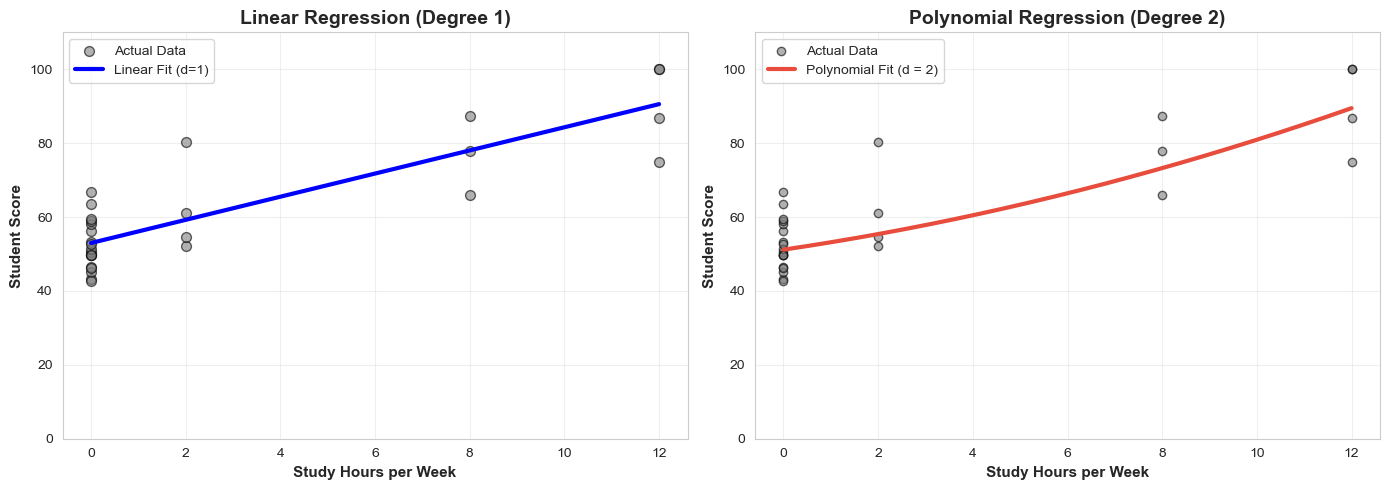

In [84]:
# Create side by side comparison
fig, axes = plt.subplots(1, 2, figsize = (14,5))

# Plot 1: Linear (Degree 1)
axes[0].scatter(x_sorted, y_sorted, alpha = 0.6, s = 50, c = 'gray', edgecolors = 'k', label = 'Actual Data')
axes[0].plot(X_range, y_smooth_linear, 'b-', linewidth = 3, label = 'Linear Fit (d=1)')
axes[0].set_xlabel('Study Hours per Week', fontsize = 11, fontweight = 'bold')
axes[0].set_ylabel('Student Score', fontsize = 11, fontweight = 'bold')
axes[0].set_title('Linear Regression (Degree 1)', fontsize = 14, fontweight = 'bold')
axes[0].legend()
axes[0].grid(True, alpha = 0.3)
axes[0].set_ylim([0, 110])

# Plot 2: Polynomial (Degree 2)
axes[1].scatter(x_sorted, y_sorted, alpha = 0.6, c = 'gray', edgecolors = 'k', label = 'Actual Data')
axes[1].plot(X_range, y_smooth_poly, '-', linewidth = 3, label = 'Polynomial Fit (d = 2)', color='#e74c3c')
axes[1].set_xlabel('Study Hours per Week', fontsize = 11, fontweight = 'bold')
axes[1].set_ylabel('Student Score', fontsize = 11, fontweight = 'bold')
axes[1].set_title('Polynomial Regression (Degree 2)', fontsize = 14, fontweight = 'bold')
axes[1].legend()
axes[1].grid(True, alpha = 0.3)
axes[1].set_ylim([0, 110])

plt.tight_layout()
plt.show()

### Combined Comparison Both Fits

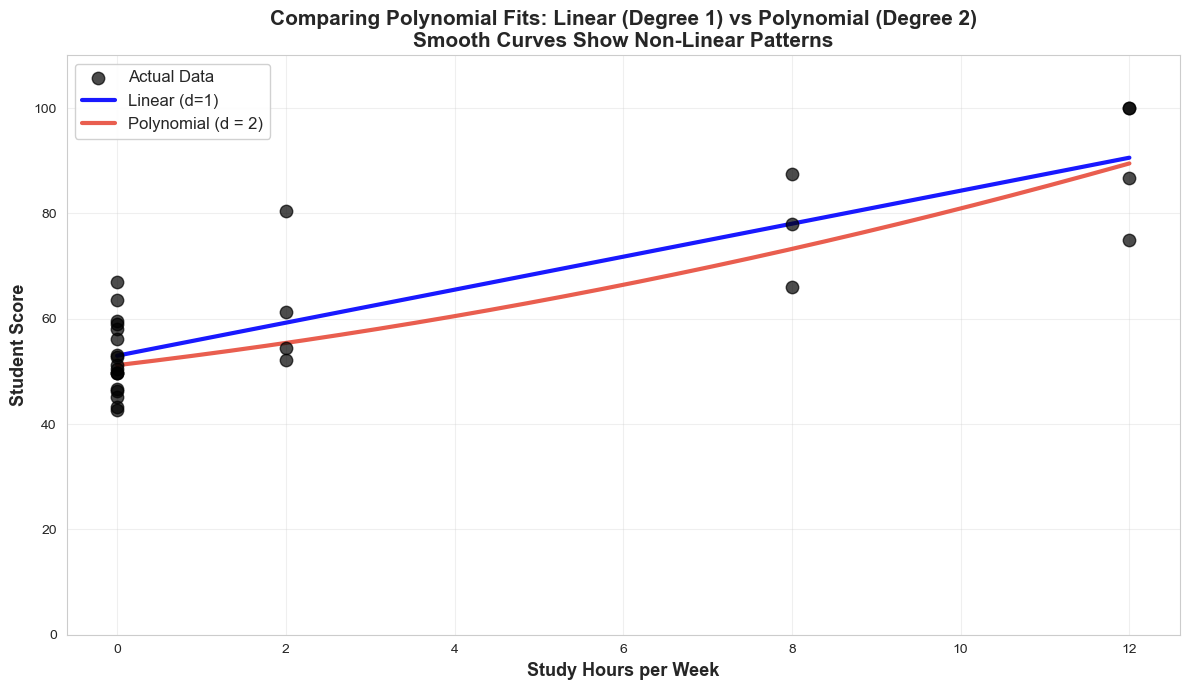


✅ Visualization Complete!

Key Observations:
• Linear (d = 1): Simple straight line
• Polynomial (d = 2): Curved fit captures non linear relationships


In [93]:
# Create Combined Plot
fig, ax = plt.subplots(figsize = [12, 7])

# Plot Actual Data
ax.scatter(x_sorted, y_sorted, alpha = 0.7, s = 80, c = 'black', edgecolors = 'k', label = 'Actual Data', zorder = 5)

# Plot smooth curves for both models
ax.plot(X_range, y_smooth_linear, 'b-', linewidth = 3, label = 'Linear (d=1)', alpha = 0.9)
ax.plot(X_range, y_smooth_poly, '-', linewidth = 3, label = 'Polynomial (d = 2)', alpha = 0.9, color = '#e74c3c')
ax.set_xlabel('Study Hours per Week', fontsize = 13, fontweight = 'bold')
ax.set_ylabel('Student Score', fontsize = 13, fontweight = 'bold')
ax.set_title('Comparing Polynomial Fits: Linear (Degree 1) vs Polynomial (Degree 2)\nSmooth Curves Show Non-Linear Patterns', 
             fontsize = 15, fontweight = 'bold')
ax.legend(fontsize = 12, loc = 'best', framealpha = 0.9)
ax.grid(True, alpha = 0.3)
ax.set_ylim([0, 110])

plt.tight_layout()
plt.show()

print("\n✅ Visualization Complete!")
print("\nKey Observations:")
print("• Linear (d = 1): Simple straight line")
print("• Polynomial (d = 2): Curved fit captures non linear relationships")

### Residual Analysis

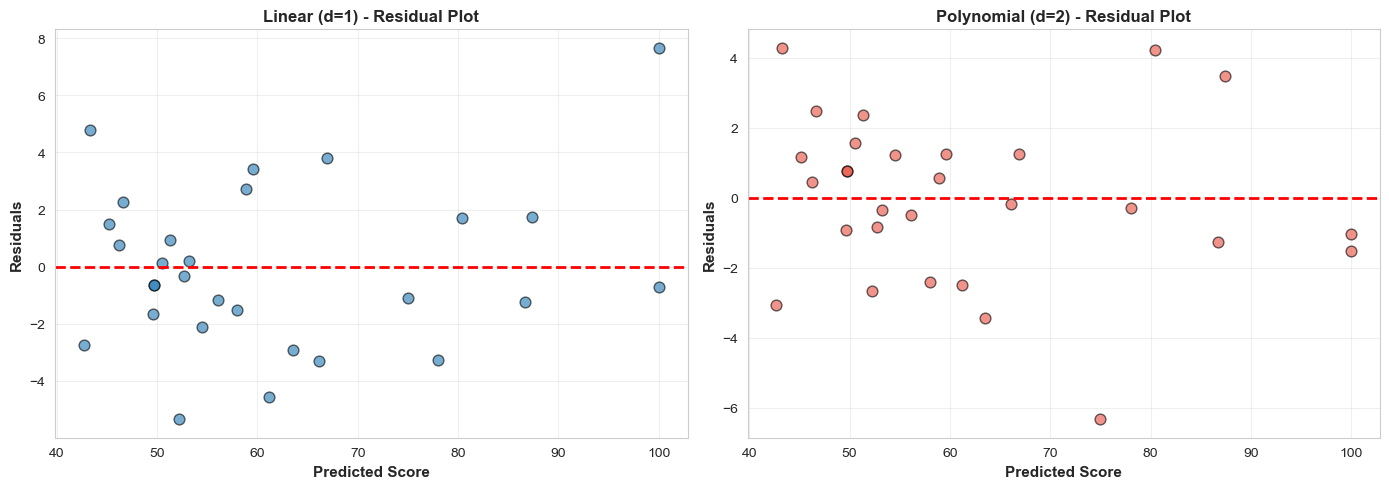


Residual Plots help identify model fit quality:
• Random scatter around 0 = Good Fit
• Patterns in residuals = Model not capturing all relationships


In [106]:
# Create residual plotsfor both models
fig, axes = plt.subplots(1, 2, figsize = [14, 5])

# Linear model residuals
residuals_linear = y_test - y_test_pred_linear
axes[0].scatter(y_test, residuals_linear, alpha = 0.6, edgecolors = 'k', s = 60)
axes[0].axhline(y = 0, color = 'r', linestyle = '--', lw = 2)
axes[0].set_xlabel('Predicted Score', fontsize = 11, fontweight = 'bold')
axes[0].set_ylabel('Residuals', fontsize = 11, fontweight = 'bold')
axes[0].set_title('Linear (d=1) - Residual Plot', fontsize = 12, fontweight = 'bold')
axes[0].grid(True, alpha = 0.3)

# Polynomial Residuals
residuals_poly = y_test - y_test_pred_poly
axes[1].scatter(y_test, residuals_poly, alpha = 0.6, edgecolors = 'k', s = 60, color='#e74c3c')
axes[1].axhline(y = 0, color = 'r', linestyle = '--', lw = 2)
axes[1].set_xlabel('Predicted Score', fontsize = 11, fontweight = 'bold')
axes[1].set_ylabel('Residuals', fontsize = 11, fontweight = 'bold')
axes[1].set_title('Polynomial (d=2) - Residual Plot', fontsize = 12, fontweight = 'bold')
axes[1].grid(True, alpha = 0.3)

plt.tight_layout()
plt.show()

print('\nResidual Plots help identify model fit quality:')
print('• Random scatter around 0 = Good Fit')
print('• Patterns in residuals = Model not capturing all relationships')

## Summary

1. **Exploratory Data Analysis (EDA)**:
   - Examined data distrubution and missing values
   - Analyzed feature corelations with target variable
   - Visualized grade and score distributions
  
2. **Linear Regression (Degree 1)**:
   - Simple straight-line fit
   - Cannot capture non-linear relationships
   - Fast and interpretable
  
3. **Polynomial Regression (Degree 2)**:
   - Captures quadratic (curved) patterns
   - Better for data with non linear relationships
   - More flexible than Linear Regression
  
### Key Metrics:
- **R² Score**: How well the model explains variance (0-1, higher is better)
- **RMSE**: Root Mean Squared Error (lower is better)
- **MAE**: Mean Absolute Error (lower is better)

### Best Practices:
- Always start with EDA for better understanding of data
- Begin with simple models (linear)
- Add complexity only if it improves performance
- Use residual plots to validate model assumptions
- Watch for overfitting (higher training R², low test R²)